In [67]:
import json
import platform
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import randint, uniform

import sklearn
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    RandomizedSearchCV,
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer,
)


from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
)
from sklearn.neural_network import MLPRegressor


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.inspection import permutation_importance
from sklearn.base import clone


import joblib

# PROJECT CONFIGURATION

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
sns.set_theme()

print(f"Python version: {platform.python_version()}")
print(f"pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"scikit-learn version: {sklearn.__version__}")


Python version: 3.11.9
pandas version: 3.0.3
NumPy version: 2.4.5
scikit-learn version: 1.8.0


In [4]:
DATA_PATH = Path("HousingPD.csv")
df_raw = pd.read_csv(DATA_PATH, dtype="object", keep_default_na=True)
print("Raw shape:", df_raw.shape)

Raw shape: (50000, 12)


In [43]:
# Automated Data Quality Report

quality_report = pd.DataFrame({
    "Data_Type": df_raw.dtypes.astype(str),
    "Missing_Count": df_raw.isna().sum(),
    "Missing_Percentage": (
        df_raw.isna().mean() * 100
    ).round(2),
    "Unique_Values": df_raw.nunique(dropna=True)
})

print("Dataset Shape:", df_raw.shape)
print("Duplicate Rows:", df_raw.duplicated().sum())

display(
    quality_report.sort_values(
        by="Missing_Percentage",
        ascending=False
    )
)


Dataset Shape: (50000, 12)
Duplicate Rows: 0


,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
property_age_years,object,6092,12.18,760
school_rating,object,5600,11.20,118
distance_to_city_km,object,4734,9.47,2528
furnishing_status,object,4594,9.19,9
bathrooms,object,4226,8.45,9
parking,object,4006,8.01,9
bedrooms,object,3577,7.15,12
location_tier,object,3569,7.14,11
stories,object,3181,6.36,7
property_type,object,2716,5.43,11


In [44]:

# Raw Data Audit: Sample Values and Invalid Entries

print("First 10 rows:")
display(df_raw.head(10))

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nRandom sample values from each column:")
for col in df_raw.columns:
    print(f"\n--- {col} ---")
    print(df_raw[col].dropna().astype(str).sample(
        n=min(10, df_raw[col].notna().sum()),
        random_state=42
    ).tolist())

print("\nDuplicate rows:", df_raw.duplicated().sum())

print("\nMissing target values (price):", df_raw["price"].isna().sum())


First 10 rows:


,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,parking,stories,location_tier,furnishing_status,property_type,school_rating,price
0,1753.0,4.0,2.0,8.5,11.13,?,3.0,Tier 1,Furnished,Independent House,8.0,13965211.0
1,805.0,2.0,2.0,3.5,6.61,2.0,2.0,Tier 2,Unfurnished,Apartment,6.0,7658858.0
2,617.0,1.0,1.0,15.4,-3,1.0,2.0,NaN,Semi-furnished,Row House,5.9,NaN
3,1054.0,2.0,2.0,NaN,3.92,NaN,2.0,Tier 1,Unfurnished,Independent House,NaN,10024557.0
4,1373.0,2.0,1.0,4.3,NaN,2.0,1.0,Tier 3,Semi-furnished,Independent House,6.3,9971621.0
5,1562.0,NaN,2.0,17.8,6.28,1.0,1.0,Tier 2,NaN,Independent House,6.4,10899629.0
6,NaN,3.0,2.0,9.4,11.78,1.0,NaN,Tier-3,Unfurnished,Villa,4.4,10662644.0
7,1532.0,2.0,1.0,150,24.31,2.0,2.0,Tier 3,NaN,Independent House,3.8,9787654.0
8,1812.0,3.0,2.0,13.5,5.88,2.0,2.0,Tier 1,Unfurnished,Independent House,5.5,11923059.0
9,2362.0,3.0,3.0,71.5,11.23,NaN,3.0,Tier 3,Semi-furnished,Villa,3.4,13703858.0



Column names:
['area_sqft', 'bedrooms', 'bathrooms', 'property_age_years', 'distance_to_city_km', 'parking', 'stories', 'location_tier', 'furnishing_status', 'property_type', 'school_rating', 'price']

Random sample values from each column:

--- area_sqft ---
['696.0', '3877.0', '1002.0', '1303.0', '1196.0', '3530.0', '673.0', '1251.0', '2634.0', '525.0']

--- bedrooms ---
['5.0', '4.0', '5.0', '2.0', '5.0', '4.0', '6.0', '4.0', '2.0', '-2']

--- bathrooms ---
['2.0', '4.0', '2.0', '1.0', '2.0', '1.0', '2.0', '3.0', '1.0', '3.0']

--- property_age_years ---
['12.9', '19.0', '18.8', '14.8', '33.7', '?', '10.0', '19.0', '20.4', '24.1']

--- distance_to_city_km ---
['11.32', '13.42', '4.28', '7.93', '3.19', '3.4', '6.42', '8.41', '7.5', '8.51']

--- parking ---
['2.0', '2.0', '1.0', '2.0', '0.0', '0.0', '1.0', '1.0', '2.0', '2.0']

--- stories ---
['1.0', '2.0', '2.0', '1.0', '2.0', '?', '2.0', '1.0', '3.0', '2.0']

--- location_tier ---
['Tier 2', 'Tier 3', 'Tier 3', 'Tier 3', 'Tier 2',

In [45]:

# Data Cleaning - Step 1: Normalize Missing Values and Categories

df = df_raw.copy()

# 1. Convert common invalid text markers to NaN
missing_markers = ["?", "unknown", "Unknown", "N/A", "n/a", "NA", ""]

df = df.replace(missing_markers, np.nan)

# 2. Standardize categorical text values
categorical_cols = [
    "location_tier",
    "furnishing_status",
    "property_type"
]

for col in categorical_cols:
    df[col] = df[col].apply(
        lambda x: x.strip().lower() if isinstance(x, str) else x
    )

# 3. Standardize furnishing category variants
df["furnishing_status"] = df["furnishing_status"].replace({
    "semi furnished": "semi-furnished",
    "semi-furnished": "semi-furnished",
    "fully furnished": "fully-furnished",
    "unfurnished": "unfurnished"
})

# 4. Display category values after normalization
for col in categorical_cols:
    print(f"\n{col} - unique values:")
    print(sorted(df[col].dropna().unique()))

print("\nShape after normalization:", df.shape)
print("Missing values after normalization:")
display(df.isna().sum().to_frame("Missing_Count"))



location_tier - unique values:
['???', 'suburban', 'tier 1', 'tier 2', 'tier 3', 'tier 4', 'tier-3', 'tier4']

furnishing_status - unique values:
['??', 'furnished', 'semi-furnished', 'unfurnished']

property_type - unique values:
['??', 'apartment', 'independent house', 'other', 'row house', 'row-house', 'villa']

Shape after normalization: (50000, 12)
Missing values after normalization:


,Missing_Count
area_sqft,2763
bedrooms,3937
bathrooms,4750
property_age_years,6580
distance_to_city_km,5210
parking,4436
stories,3552
location_tier,3917
furnishing_status,4989
property_type,3068


In [46]:

# Data Cleaning - Step 2: Numeric Conversion and Category Validation

# 1. Convert invalid category markers into missing values
invalid_markers = ["??", "???", "unknown", "n/a", "na", "?"]

df = df.replace(invalid_markers, np.nan)

# 2. Standardize location tiers
df["location_tier"] = df["location_tier"].replace({
    "tier-1": "tier 1",
    "tier-2": "tier 2",
    "tier-3": "tier 3",
    "tier-4": "tier 4",
    "tier4": "tier 4",
    "suburban": "suburban"
})

# 3. Standardize property types
df["property_type"] = df["property_type"].replace({
    "row-house": "row house"
})

# 4. Convert numeric columns safely
numeric_cols = [
    "area_sqft",
    "bedrooms",
    "bathrooms",
    "property_age_years",
    "distance_to_city_km",
    "parking",
    "stories",
    "school_rating",
    "price"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 5. Show data types after conversion
print("Updated data types:")
display(df.dtypes.to_frame("Data_Type"))

# 6. Check categories after standardization
for col in ["location_tier", "furnishing_status", "property_type"]:
    print(f"\n{col}:")
    print(sorted(df[col].dropna().unique()))

# 7. Check missing values
print("\nMissing values after conversion:")
display(df.isna().sum().to_frame("Missing_Count"))


Updated data types:


,Data_Type
area_sqft,float64
bedrooms,float64
bathrooms,float64
property_age_years,float64
distance_to_city_km,float64
parking,float64
stories,float64
location_tier,str
furnishing_status,str
property_type,str



location_tier:
['suburban', 'tier 1', 'tier 2', 'tier 3', 'tier 4']

furnishing_status:
['furnished', 'semi-furnished', 'unfurnished']

property_type:
['apartment', 'independent house', 'other', 'row house', 'villa']

Missing values after conversion:


,Missing_Count
area_sqft,3123
bedrooms,4119
bathrooms,4750
property_age_years,6580
distance_to_city_km,5210
parking,4616
stories,3552
location_tier,4261
furnishing_status,5382
property_type,3415


In [3]:
TARGET = "price"
print("Shape:", df_raw.shape)
print("\nDtypes:")
display(df_raw.dtypes.to_frame("raw_dtype"))
print("\nMissingness:")
null_report = pd.DataFrame({
    "null_count": df_raw.isna().sum(),
    "null_pct": (df_raw.isna().mean()*100).round(2),
    "distinct_non_null": df_raw.nunique(dropna=True)
}).sort_values("null_pct", ascending=False)
display(null_report)
print("Exact duplicate rows:", df_raw.duplicated().sum())
display(df_raw.sample(8, random_state=RANDOM_STATE))

Shape: (50000, 12)

Dtypes:


,raw_dtype
area_sqft,object
bedrooms,object
bathrooms,object
property_age_years,object
distance_to_city_km,object
parking,object
stories,object
location_tier,object
furnishing_status,object
property_type,object



Missingness:


,null_count,null_pct,distinct_non_null
property_age_years,6092,12.18,760
school_rating,5600,11.20,118
distance_to_city_km,4734,9.47,2528
furnishing_status,4594,9.19,9
bathrooms,4226,8.45,9
parking,4006,8.01,9
bedrooms,3577,7.15,12
location_tier,3569,7.14,11
stories,3181,6.36,7
property_type,2716,5.43,11


Exact duplicate rows: 0


,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,parking,stories,location_tier,furnishing_status,property_type,school_rating,price
33553,609.0,2.0,1.0,NaN,3.57,2.0,3.0,Tier 3,Furnished,Row House,5.8,6660859.0
9427,2506.0,4.0,3.0,26.7,10.52,unknown,2.0,Tier 1,Furnished,unknown,NaN,18144574.0
199,975.0,3.0,3.0,4.4,4.59,1.0,2.0,Tier 2,NaN,Villa,7.7,9464112.0
12447,944.0,?,2.0,NaN,8.17,1.0,1.0,Tier 2,semi-furnished,Independent House,7.9,7990477.0
39489,1230.0,1.0,2.0,14.9,NaN,4.0,3.0,Tier 3,Furnished,NaN,5.7,8926522.0
42724,1673.0,3.0,2.0,17.8,NaN,2.0,2.0,Tier 3,Semi-furnished,Apartment,6.5,11887725.0
10822,1220.0,1.0,2.0,29.1,4.96,1.0,2.0,Tier 2,unknown,Apartment,6.3,8869021.0
49498,1669.0,3.0,2.0,14.5,4.64,0.0,2.0,Tier 3,Unfurnished,Apartment,5.9,9776868.0


In [47]:

# Verify the cleaned dataset (df)

print("Cleaned dataset shape:", df.shape)

print("\nUpdated data types:")
display(df.dtypes.to_frame("Data_Type"))

print("\nRemaining missing values:")
display(df.isna().sum().to_frame("Missing_Count"))

print("\nSample cleaned rows:")
display(df.sample(8, random_state=42))

print("\nUnique categories after cleaning:")
for col in ["location_tier", "furnishing_status", "property_type"]:
    print(f"\n{col}:")
    print(sorted(df[col].dropna().unique()))


Cleaned dataset shape: (50000, 12)

Updated data types:


,Data_Type
area_sqft,float64
bedrooms,float64
bathrooms,float64
property_age_years,float64
distance_to_city_km,float64
parking,float64
stories,float64
location_tier,str
furnishing_status,str
property_type,str



Remaining missing values:


,Missing_Count
area_sqft,3123
bedrooms,4119
bathrooms,4750
property_age_years,6580
distance_to_city_km,5210
parking,4616
stories,3552
location_tier,4261
furnishing_status,5382
property_type,3415



Sample cleaned rows:


,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,parking,stories,location_tier,furnishing_status,property_type,school_rating,price
33553,609.0,2.0,1.0,NaN,3.57,2.0,3.0,tier 3,furnished,row house,5.8,6660859.0
9427,2506.0,4.0,3.0,26.7,10.52,NaN,2.0,tier 1,furnished,NaN,NaN,18144574.0
199,975.0,3.0,3.0,4.4,4.59,1.0,2.0,tier 2,NaN,villa,7.7,9464112.0
12447,944.0,NaN,2.0,NaN,8.17,1.0,1.0,tier 2,semi-furnished,independent house,7.9,7990477.0
39489,1230.0,1.0,2.0,14.9,NaN,4.0,3.0,tier 3,furnished,NaN,5.7,8926522.0
42724,1673.0,3.0,2.0,17.8,NaN,2.0,2.0,tier 3,semi-furnished,apartment,6.5,11887725.0
10822,1220.0,1.0,2.0,29.1,4.96,1.0,2.0,tier 2,NaN,apartment,6.3,8869021.0
49498,1669.0,3.0,2.0,14.5,4.64,0.0,2.0,tier 3,unfurnished,apartment,5.9,9776868.0



Unique categories after cleaning:

location_tier:
['suburban', 'tier 1', 'tier 2', 'tier 3', 'tier 4']

furnishing_status:
['furnished', 'semi-furnished', 'unfurnished']

property_type:
['apartment', 'independent house', 'other', 'row house', 'villa']


In [48]:

# Step 3: Numeric Range Validation

validation_rules = {
    "area_sqft": lambda s: s <= 0,
    "bedrooms": lambda s: (s < 0) | (s > 20),
    "bathrooms": lambda s: (s < 0) | (s > 20),
    "property_age_years": lambda s: (s < 0) | (s > 150),
    "distance_to_city_km": lambda s: s < 0,
    "parking": lambda s: (s < 0) | (s > 20),
    "stories": lambda s: (s < 0) | (s > 100),
    "school_rating": lambda s: (s < 0) | (s > 10),
    "price": lambda s: s <= 0
}

validation_report = []

for col, rule in validation_rules.items():
    invalid_mask = df[col].notna() & rule(df[col])

    validation_report.append({
        "Column": col,
        "Invalid_Count": int(invalid_mask.sum()),
        "Invalid_Percentage": round(
            invalid_mask.mean() * 100, 2
        )
    })

validation_report = pd.DataFrame(validation_report)

print("Numeric Range Validation Report:")
display(validation_report)

# Show examples of invalid values
for col, rule in validation_rules.items():
    invalid_mask = df[col].notna() & rule(df[col])

    if invalid_mask.any():
        print(f"\nInvalid examples in {col}:")
        display(df.loc[invalid_mask, [col]].head(10))


Numeric Range Validation Report:


,Column,Invalid_Count,Invalid_Percentage
0,area_sqft,0,0.00
1,bedrooms,170,0.34
2,bathrooms,221,0.44
3,property_age_years,268,0.54
4,distance_to_city_km,251,0.50
5,parking,192,0.38
6,stories,178,0.36
7,school_rating,419,0.84
8,price,0,0.00



Invalid examples in bedrooms:


,bedrooms
500,-2.0
1228,-2.0
1798,-2.0
3244,-2.0
3303,-2.0
3684,-2.0
3808,-2.0
3938,-2.0
4119,-2.0
4473,-2.0



Invalid examples in bathrooms:


...

,parking
88,-1.0
183,-1.0
688,-1.0
695,-1.0
1376,-1.0
1494,-1.0
1669,-1.0
1898,-1.0
2005,-1.0
2064,-1.0



Invalid examples in stories:


,stories
185,-1.0
570,-1.0
1213,-1.0
1468,-1.0
1620,-1.0
1653,-1.0
2108,-1.0
2272,-1.0
3158,-1.0
3729,-1.0



Invalid examples in school_rating:


,school_rating
171,15.0
189,-2.0
264,15.0
507,15.0
738,15.0
765,-2.0
1092,15.0
1189,15.0
1395,15.0
1404,15.0


In [49]:

# Step 4: Replace Invalid Numeric Values with NaN

invalid_rules = {
    "area_sqft": lambda s: s <= 0,
    "bedrooms": lambda s: (s < 0) | (s > 20),
    "bathrooms": lambda s: (s < 0) | (s > 20),
    "property_age_years": lambda s: (s < 0) | (s > 150),
    "distance_to_city_km": lambda s: s < 0,
    "parking": lambda s: (s < 0) | (s > 20),
    "stories": lambda s: (s < 0) | (s > 100),
    "school_rating": lambda s: (s < 0) | (s > 10),
    "price": lambda s: s <= 0
}

invalid_counts_before = {}

for col, rule in invalid_rules.items():
    invalid_mask = df[col].notna() & rule(df[col])
    invalid_counts_before[col] = int(invalid_mask.sum())
    df.loc[invalid_mask, col] = np.nan

print("Invalid values converted to NaN:")
display(
    pd.Series(invalid_counts_before, name="Converted_Count")
    .to_frame()
)

print("\nMissing values after validation:")
display(df.isna().sum().to_frame("Missing_Count"))


Invalid values converted to NaN:


,Converted_Count
area_sqft,0
bedrooms,170
bathrooms,221
property_age_years,268
distance_to_city_km,251
parking,192
stories,178
school_rating,419
price,0



Missing values after validation:


,Missing_Count
area_sqft,3123
bedrooms,4289
bathrooms,4971
property_age_years,6848
distance_to_city_km,5461
parking,4808
stories,3730
location_tier,4261
furnishing_status,5382
property_type,3415


In [50]:

# Step 5A: Remove rows where the target (price) is missing

print("Rows before target cleaning:", len(df))
print("Missing price values:", df[TARGET].isna().sum())

df_model = df.dropna(subset=[TARGET]).copy()

print("\nRows after target cleaning:", len(df_model))
print("Remaining missing target values:", df_model[TARGET].isna().sum())
print("Rows removed:", len(df) - len(df_model))


Rows before target cleaning: 50000
Missing price values: 400

Rows after target cleaning: 49600
Remaining missing target values: 0
Rows removed: 400


In [51]:

# Step 5B: Separate Features (X) and Target (y)

X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in features:")
display(X.isna().sum().to_frame("Missing_Count"))

print("\nTarget summary:")
display(y.describe().to_frame("price_summary"))


Feature matrix shape: (49600, 11)
Target shape: (49600,)

Missing values in features:


,Missing_Count
area_sqft,3104
bedrooms,4247
bathrooms,4930
property_age_years,6810
distance_to_city_km,5415
parking,4772
stories,3705
location_tier,4225
furnishing_status,5332
property_type,3385



Target summary:


,price_summary
count,4.960000e+04
mean,1.069860e+07
std,4.086896e+06
min,1.228973e+06
25%,7.862626e+06
50%,9.966366e+06
75%,1.266577e+07
max,3.686682e+07


In [52]:

# Step 6: Split data into training and testing sets
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nMissing values in training features:")
display(X_train.isna().sum().to_frame("Missing_Count"))

print("\nMissing values in testing features:")
display(X_test.isna().sum().to_frame("Missing_Count"))


Training features: (39680, 11)
Testing features: (9920, 11)
Training target: (39680,)
Testing target: (9920,)

Missing values in training features:


,Missing_Count
area_sqft,2513
bedrooms,3379
bathrooms,3925
property_age_years,5496
distance_to_city_km,4345
parking,3833
stories,2975
location_tier,3379
furnishing_status,4277
property_type,2696



Missing values in testing features:


,Missing_Count
area_sqft,591
bedrooms,868
bathrooms,1005
property_age_years,1314
distance_to_city_km,1070
parking,939
stories,730
location_tier,846
furnishing_status,1055
property_type,689


In [54]:

# Step 7: Build a Leakage-Safe Preprocessing Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Numerical preprocessing: fill missing values with median
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: fill missing values and encode categories
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessing pipeline created successfully.")


Numerical features: ['area_sqft', 'bedrooms', 'bathrooms', 'property_age_years', 'distance_to_city_km', 'parking', 'stories', 'school_rating']
Categorical features: ['location_tier', 'furnishing_status', 'property_type']

Preprocessing pipeline created successfully.


In [55]:

# Step 8: Baseline Model - Predict the Training Mean

from sklearn.dummy import DummyRegressor
# Create a complete baseline pipeline
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="mean"))
])

# Train the baseline model
baseline_model.fit(X_train, y_train)

# Predict on test data
baseline_pred = baseline_model.predict(X_test)

# Evaluate baseline performance
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

baseline_results = pd.DataFrame([{
    "Model": "Mean Baseline",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
    "R2_Score": baseline_r2
}])

display(baseline_results.style.format({
    "MAE": "{:,.2f}",
    "RMSE": "{:,.2f}",
    "R2_Score": "{:.4f}"
}))


,Model,MAE,RMSE,R2_Score
0,Mean Baseline,"3,106,811.63","4,120,029.96",-0.0000


In [56]:

# Step 9: Train and Compare Multiple ML Models

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=10.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.1,
        random_state=42
    )
}

fitted = {}
results = []

for model_name, estimator in models.items():
    print(f"Training: {model_name}")

    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    fitted[model_name] = model_pipeline

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2_Score": r2,
        "R2_Percentage": r2 * 100
    })

model_results = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(model_results.style.format({
    "MAE": "{:,.2f}",
    "RMSE": "{:,.2f}",
    "R2_Score": "{:.4f}",
    "R2_Percentage": "{:.2f}%"
}))


Training: Linear Regression
Training: Ridge Regression
Training: Random Forest
Training: Extra Trees
Training: Hist Gradient Boosting


,Model,MAE,RMSE,R2_Score,R2_Percentage
0,Hist Gradient Boosting,"738,765.97","1,016,978.06",0.9391,93.91%
1,Random Forest,"768,369.17","1,040,476.92",0.9362,93.62%
2,Extra Trees,"803,618.40","1,089,475.46",0.9301,93.01%
3,Linear Regression,"1,232,583.00","1,760,700.65",0.8174,81.74%
4,Ridge Regression,"1,232,665.28","1,760,756.33",0.8174,81.74%


In [68]:

# Step 10: Cross-Validation of the Top 3 Models
top_models = [
    "Hist Gradient Boosting",
    "Random Forest",
    "Extra Trees"
]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for model_name in top_models:
    print("Cross-validating:", model_name)

    scores = cross_validate(
        fitted[model_name],
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=1,
        return_train_score=False
    )

    cv_results.append({
        "Model": model_name,
        "Mean_CV_MAE": -scores["test_mae"].mean(),
        "Mean_CV_RMSE": -scores["test_rmse"].mean(),
        "Mean_CV_R2": scores["test_r2"].mean(),
        "Std_CV_R2": scores["test_r2"].std()
    })

cv_results_df = (
    pd.DataFrame(cv_results)
    .sort_values("Mean_CV_RMSE")
    .reset_index(drop=True)
)

display(cv_results_df.style.format({
    "Mean_CV_MAE": "{:,.2f}",
    "Mean_CV_RMSE": "{:,.2f}",
    "Mean_CV_R2": "{:.4f}",
    "Std_CV_R2": "{:.4f}"
}))


Cross-validating: Hist Gradient Boosting
Cross-validating: Random Forest
Cross-validating: Extra Trees


,Model,Mean_CV_MAE,Mean_CV_RMSE,Mean_CV_R2,Std_CV_R2
0,Hist Gradient Boosting,"751,206.11","1,038,690.33",0.9350,0.0039
1,Random Forest,"779,171.14","1,054,377.91",0.9331,0.0026
2,Extra Trees,"816,539.87","1,113,469.16",0.9253,0.0034


In [58]:

# Step 11: Hyperparameter Tuning for Hist Gradient Boosting
from scipy.stats import randint, uniform

tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingRegressor(random_state=42))
])

param_distributions = {
    "model__learning_rate": uniform(0.03, 0.17),
    "model__max_iter": randint(100, 301),
    "model__max_leaf_nodes": randint(15, 41),
    "model__min_samples_leaf": randint(10, 41),
    "model__l2_regularization": uniform(0.0, 2.0)
}

search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)

print("\nBest CV RMSE:", round(-search.best_score_, 2))


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters:
{'model__l2_regularization': np.float64(0.6674172222780437), 'model__learning_rate': np.float64(0.05428735904672993), 'model__max_iter': 230, 'model__max_leaf_nodes': 36, 'model__min_samples_leaf': 30}

Best CV RMSE: 1054002.99


In [59]:

# Step 12: Evaluate the Tuned Model on the Held-Out Test Set
final_model = search.best_estimator_

# Predict using the untouched test set
test_pred = final_model.predict(X_test)

# Calculate evaluation metrics
final_mae = mean_absolute_error(y_test, test_pred)
final_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
final_r2 = r2_score(y_test, test_pred)

final_results = pd.DataFrame([{
    "Model": "Tuned Hist Gradient Boosting",
    "MAE": final_mae,
    "RMSE": final_rmse,
    "R2_Score": final_r2,
    "R2_Percentage": final_r2 * 100
}])

display(final_results.style.format({
    "MAE": "{:,.2f}",
    "RMSE": "{:,.2f}",
    "R2_Score": "{:.4f}",
    "R2_Percentage": "{:.2f}%"
}))

# Compare with the earlier baseline
print("\nBaseline MAE:", round(baseline_mae, 2))
print("Final model MAE:", round(final_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))
print("Final model RMSE:", round(final_rmse, 2))


,Model,MAE,RMSE,R2_Score,R2_Percentage
0,Tuned Hist Gradient Boosting,"737,860.26","1,020,095.90",0.9387,93.87%



Baseline MAE: 3106811.63
Final model MAE: 737860.26
Baseline RMSE: 4120029.96
Final model RMSE: 1020095.9


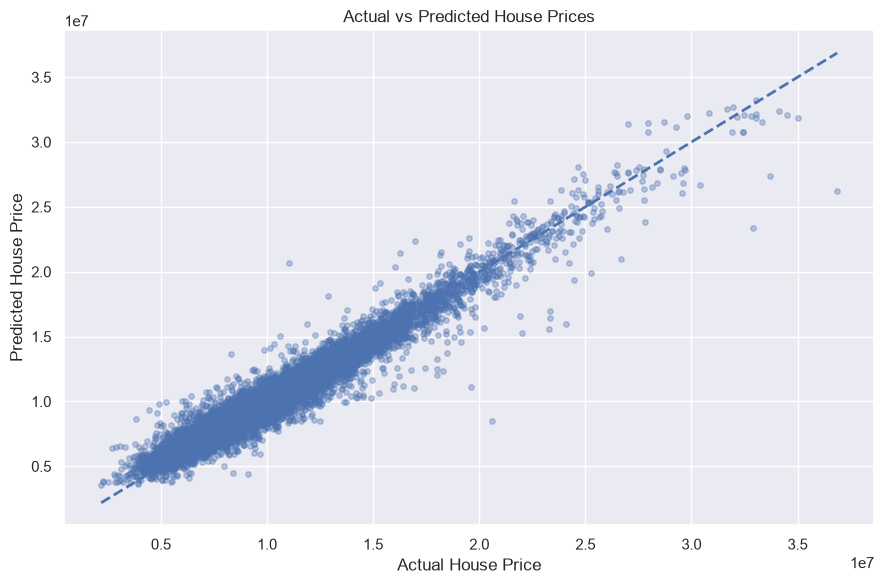

In [60]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    test_pred,
    alpha=0.35,
    s=15
)

# Ideal prediction reference line
min_price = min(y_test.min(), test_pred.min())
max_price = max(y_test.max(), test_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    linewidth=2
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()


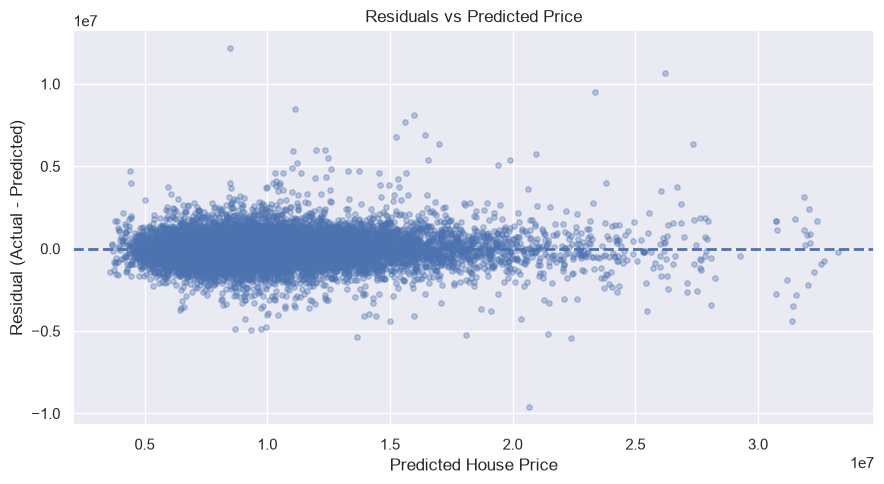

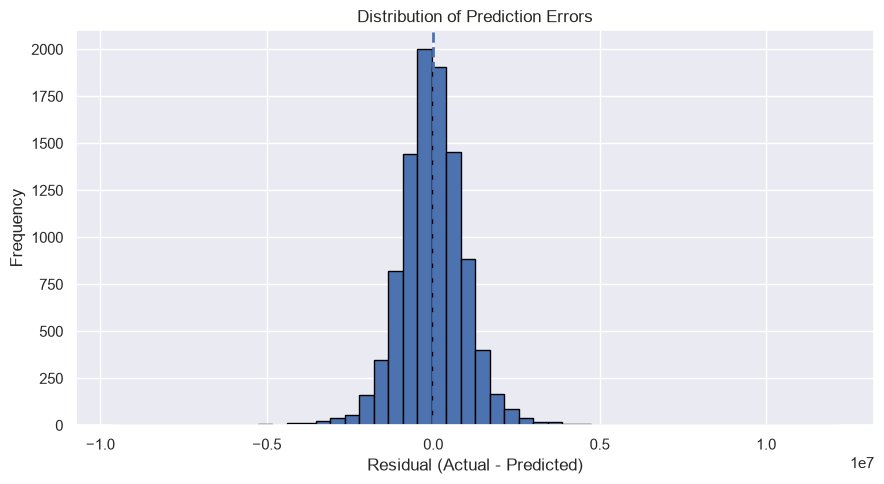

,Value
count,9.920000e+03
mean,-1.101789e+04
std,1.020088e+06
min,-9.630236e+06
25%,-5.953990e+05
50%,-3.526349e+04
75%,5.590090e+05
max,1.215209e+07


Mean residual: -11017.89
Median absolute error: 578357.79


In [61]:
residuals = y_test - test_pred

# 1. Residuals vs Predicted Price
plt.figure(figsize=(9, 5))
plt.scatter(test_pred, residuals, alpha=0.35, s=15)
plt.axhline(y=0, linestyle="--", linewidth=2)
plt.xlabel("Predicted House Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Predicted Price")
plt.tight_layout()
plt.show()

# 2. Distribution of Residuals
plt.figure(figsize=(9, 5))
plt.hist(residuals, bins=50, edgecolor="black")
plt.axvline(x=0, linestyle="--", linewidth=2)
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.tight_layout()
plt.show()

# 3. Residual summary
residual_summary = pd.Series(residuals, name="Residual").describe()
display(residual_summary.to_frame("Value"))

print("Mean residual:", round(residuals.mean(), 2))
print("Median absolute error:", round(np.median(np.abs(residuals)), 2))


In [62]:

# Step 15: Inspect the Largest Prediction Errors

error_analysis = X_test.copy()

error_analysis["Actual_Price"] = y_test
error_analysis["Predicted_Price"] = test_pred
error_analysis["Residual"] = y_test - test_pred
error_analysis["Absolute_Error"] = np.abs(
    error_analysis["Residual"]
)

# Show the 15 houses with the largest absolute errors
largest_errors = error_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
).head(15)

display(
    largest_errors.style.format({
        "Actual_Price": "{:,.0f}",
        "Predicted_Price": "{:,.0f}",
        "Residual": "{:,.0f}",
        "Absolute_Error": "{:,.0f}"
    })
)

print(
    "\nMean absolute error:",
    round(error_analysis["Absolute_Error"].mean(), 2)
)


,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,parking,stories,location_tier,furnishing_status,property_type,school_rating,Actual_Price,Predicted_Price,Residual,Absolute_Error
37106,173.000000,6.000000,4.000000,19.100000,16.830000,1.000000,nan,tier 3,furnished,apartment,8.000000,"20,616,134","8,464,046","12,152,088","12,152,088"
43332,nan,8.000000,5.000000,7.400000,2.460000,1.000000,3.000000,tier 1,unfurnished,villa,8.500000,"36,866,817","26,203,236","10,663,581","10,663,581"
49046,21161.000000,4.000000,4.000000,14.700000,3.410000,0.000000,2.000000,tier 3,nan,independent house,5.600000,"11,056,290","20,686,526","-9,630,236","9,630,236"
32852,nan,8.000000,6.000000,39.300000,nan,2.000000,2.000000,tier 2,semi-furnished,apartment,6.900000,"32,883,389","23,369,588","9,513,801","9,513,801"
23001,nan,nan,3.000000,nan,7.380000,2.000000,3.000000,tier 2,furnished,apartment,8.300000,"19,623,597","11,130,577","8,493,020","8,493,020"
35161,4513.000000,nan,nan,3.400000,11.980000,1.000000,nan,tier 3,semi-furnished,apartment,6.200000,"24,078,559","15,961,026","8,117,533","8,117,533"
9084,nan,nan,5.000000,nan,3.090000,2.000000,1.000000,nan,semi-furnished,apartment,7.500000,"23,285,343","15,603,631","7,681,712","7,681,712"
20672,nan,6.000000,4.000000,31.300000,4.650000,2.000000,2.000000,nan,semi-furnished,apartment,7.300000,"23,329,689","16,428,957","6,900,732","6,900,732"
41875,nan,nan,5.000000,nan,nan,2.000000,nan,tier 3,semi-furnished,apartment,3.700000,"22,024,523","15,261,807","6,762,716","6,762,716"
5360,6500.000000,8.000000,nan,17.500000,5.860000,2.000000,1.000000,tier 3,unfurnished,apartment,9.900000,"33,684,034","27,344,518","6,339,516","6,339,516"



Mean absolute error: 737860.26


Calculating permutation importance...


,Feature,Importance_Mean,Importance_Std
0,area_sqft,"3,502,557.1417","56,985.6793"
1,bedrooms,"937,490.6191","30,809.0794"
2,location_tier,"379,330.8359","20,021.8664"
3,bathrooms,"239,558.5754","21,621.0750"
4,property_type,"93,329.7197","5,762.7763"
5,furnishing_status,"49,911.1455","5,762.2439"
6,property_age_years,"29,468.2052","4,656.0061"
7,distance_to_city_km,"11,351.8730","2,690.9435"
8,school_rating,"7,862.8230","1,462.6192"
9,stories,"4,376.8705",205.5302


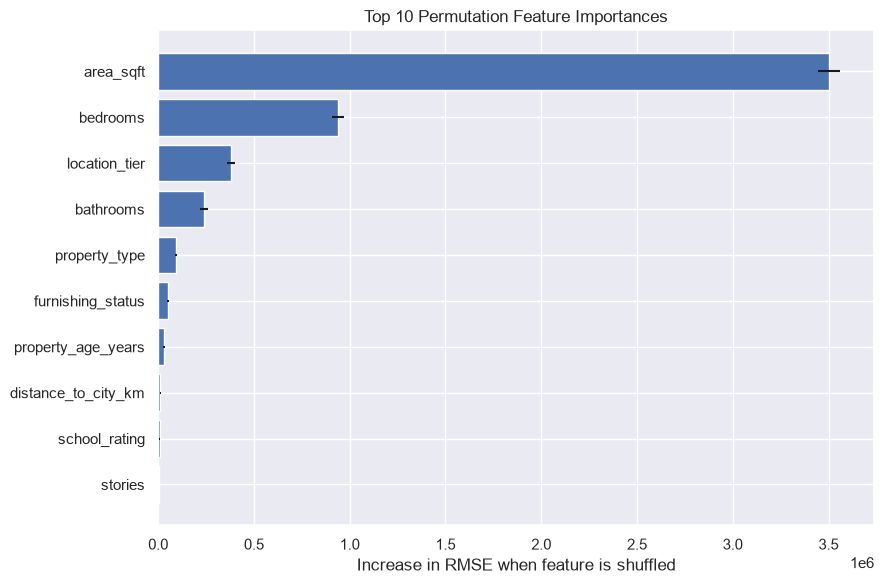

In [63]:
from sklearn.inspection import permutation_importance
# Use a reproducible sample to reduce computation time
sample_size = min(2000, len(X_test))
X_importance = X_test.sample(
    n=sample_size,
    random_state=42
)
y_importance = y_test.loc[X_importance.index]

print("Calculating permutation importance...")

importance_result = permutation_importance(
    final_model,
    X_importance,
    y_importance,
    scoring="neg_root_mean_squared_error",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": X_importance.columns,
    "Importance_Mean": importance_result.importances_mean,
    "Importance_Std": importance_result.importances_std
}).sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

display(importance_df.style.format({
    "Importance_Mean": "{:,.4f}",
    "Importance_Std": "{:,.4f}"
}))

# Plot the top 10 features
top_features = importance_df.head(10).sort_values(
    "Importance_Mean"
)

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance_Mean"],
    xerr=top_features["Importance_Std"]
)
plt.xlabel("Increase in RMSE when feature is shuffled")
plt.title("Top 10 Permutation Feature Importances")
plt.tight_layout()
plt.show()


In [64]:

# Step 17: Save the Trained Model

import joblib
from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "house_price_model.joblib"

joblib.dump(final_model, MODEL_PATH)

print("Model saved successfully!")
print("Saved location:", MODEL_PATH.resolve())
print("Model file size (KB):", round(MODEL_PATH.stat().st_size / 1024, 2))


Model saved successfully!
Saved location: C:\Users\anami\HPP\models\house_price_model.joblib
Model file size (KB): 956.85


In [65]:
MODEL_PATH = Path("models/house_price_model.joblib")

loaded_model = joblib.load(MODEL_PATH)

# Example house details
new_house = pd.DataFrame([{
    "area_sqft": 1500,
    "bedrooms": 3,
    "bathrooms": 2,
    "property_age_years": 5,
    "distance_to_city_km": 5.0,
    "parking": 1,
    "stories": 2,
    "location_tier": "tier 2",
    "furnishing_status": "semi-furnished",
    "property_type": "apartment",
    "school_rating": 8.0
}])

predicted_price = loaded_model.predict(new_house)[0]

print("Predicted House Price: ₹{:,.2f}".format(predicted_price))


Predicted House Price: ₹10,492,178.49


In [66]:
original_prediction = final_model.predict(new_house)[0]

# Predict using the saved and reloaded model
reloaded_model = joblib.load(MODEL_PATH)
reloaded_prediction = reloaded_model.predict(new_house)[0]

print("Original model prediction: ₹{:,.2f}".format(original_prediction))
print("Reloaded model prediction: ₹{:,.2f}".format(reloaded_prediction))

if np.isclose(original_prediction, reloaded_prediction):
    print("\nPASS: Both models produce the same prediction.")
else:
    print("\nFAIL: Predictions do not match.")


Original model prediction: ₹10,492,178.49
Reloaded model prediction: ₹10,492,178.49

PASS: Both models produce the same prediction.


In [53]:
assert df_raw.shape == (50000, 12), f"Expected 50,000 × 12, got {df_raw.shape}"
display(df_raw.head(10))

,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,parking,stories,location_tier,furnishing_status,property_type,school_rating,price
0,1753.0,4.0,2.0,8.5,11.13,?,3.0,Tier 1,Furnished,Independent House,8.0,13965211.0
1,805.0,2.0,2.0,3.5,6.61,2.0,2.0,Tier 2,Unfurnished,Apartment,6.0,7658858.0
2,617.0,1.0,1.0,15.4,-3,1.0,2.0,NaN,Semi-furnished,Row House,5.9,NaN
3,1054.0,2.0,2.0,NaN,3.92,NaN,2.0,Tier 1,Unfurnished,Independent House,NaN,10024557.0
4,1373.0,2.0,1.0,4.3,NaN,2.0,1.0,Tier 3,Semi-furnished,Independent House,6.3,9971621.0
5,1562.0,NaN,2.0,17.8,6.28,1.0,1.0,Tier 2,NaN,Independent House,6.4,10899629.0
6,NaN,3.0,2.0,9.4,11.78,1.0,NaN,Tier-3,Unfurnished,Villa,4.4,10662644.0
7,1532.0,2.0,1.0,150,24.31,2.0,2.0,Tier 3,NaN,Independent House,3.8,9787654.0
8,1812.0,3.0,2.0,13.5,5.88,2.0,2.0,Tier 1,Unfurnished,Independent House,5.5,11923059.0
9,2362.0,3.0,3.0,71.5,11.23,NaN,3.0,Tier 3,Semi-furnished,Villa,3.4,13703858.0


In [6]:
TARGET = "price"
print("Shape:", df_raw.shape)
print("\nDtypes:")
display(df_raw.dtypes.to_frame("raw_dtype"))
print("\nMissingness:")

Shape: (50000, 12)

Dtypes:


,raw_dtype
area_sqft,object
bedrooms,object
bathrooms,object
property_age_years,object
distance_to_city_km,object
parking,object
stories,object
location_tier,object
furnishing_status,object
property_type,object



Missingness:


In [7]:
null_report = pd.DataFrame({
    "null_count": df_raw.isna().sum(),
    "null_pct": (df_raw.isna().mean()*100).round(2),
    "distinct_non_null": df_raw.nunique(dropna=True)
}).sort_values("null_pct", ascending=False)
display(null_report)
print("Exact duplicate rows:", df_raw.duplicated().sum())
display(df_raw.sample(8, random_state=RANDOM_STATE))

,null_count,null_pct,distinct_non_null
property_age_years,6092,12.18,760
school_rating,5600,11.20,118
distance_to_city_km,4734,9.47,2528
furnishing_status,4594,9.19,9
bathrooms,4226,8.45,9
parking,4006,8.01,9
bedrooms,3577,7.15,12
location_tier,3569,7.14,11
stories,3181,6.36,7
property_type,2716,5.43,11


Exact duplicate rows: 0


,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,parking,stories,location_tier,furnishing_status,property_type,school_rating,price
33553,609.0,2.0,1.0,NaN,3.57,2.0,3.0,Tier 3,Furnished,Row House,5.8,6660859.0
9427,2506.0,4.0,3.0,26.7,10.52,unknown,2.0,Tier 1,Furnished,unknown,NaN,18144574.0
199,975.0,3.0,3.0,4.4,4.59,1.0,2.0,Tier 2,NaN,Villa,7.7,9464112.0
12447,944.0,?,2.0,NaN,8.17,1.0,1.0,Tier 2,semi-furnished,Independent House,7.9,7990477.0
39489,1230.0,1.0,2.0,14.9,NaN,4.0,3.0,Tier 3,Furnished,NaN,5.7,8926522.0
42724,1673.0,3.0,2.0,17.8,NaN,2.0,2.0,Tier 3,Semi-furnished,Apartment,6.5,11887725.0
10822,1220.0,1.0,2.0,29.1,4.96,1.0,2.0,Tier 2,unknown,Apartment,6.3,8869021.0
49498,1669.0,3.0,2.0,14.5,4.64,0.0,2.0,Tier 3,Unfurnished,Apartment,5.9,9776868.0


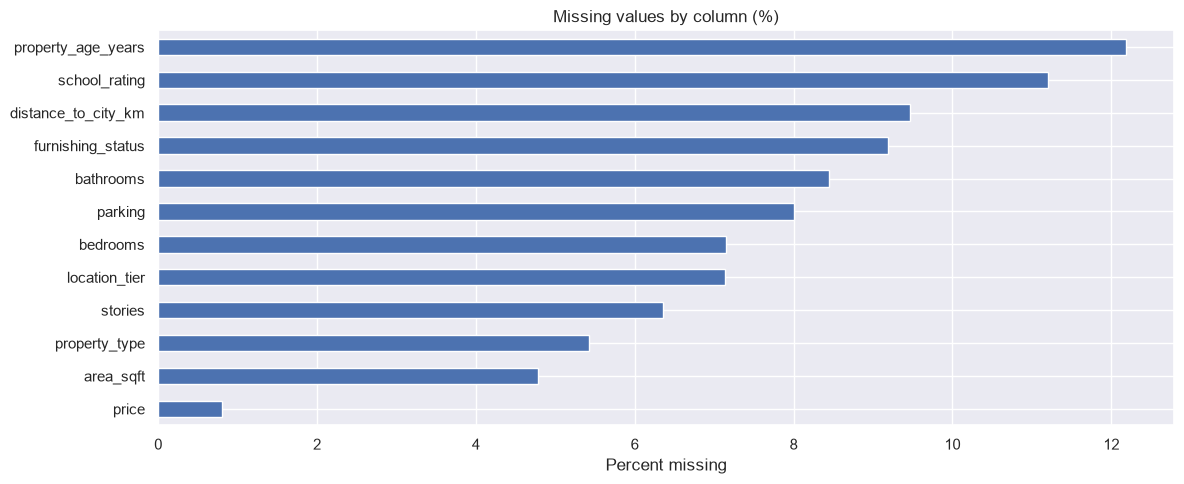

In [8]:
plt.figure(figsize=(12, 5))
null_report["null_pct"].sort_values().plot(kind="barh")
plt.title("Missing values by column (%)")
plt.xlabel("Percent missing")
plt.tight_layout()
plt.show()

In [9]:
for col in ["location_tier", "furnishing_status", "property_type"]:
    print("\n", col, "raw top categories:")
    display(df_raw[col].value_counts(dropna=False).head(15).to_frame("count"))


 location_tier raw top categories:


,count
location_tier,
Tier 3,15899
Tier 2,13525
Tier 1,7487
Tier 4,7095
NaN,3569
tier 1,354
TIER 2,352
Tier-3,348
unknown,348



 furnishing_status raw top categories:


,count
furnishing_status,
Semi-furnished,19021
Unfurnished,14648
Furnished,9392
NaN,4594
furnished,415
unknown,395
Semi Furnished,393
??,393
semi-furnished,378



 property_type raw top categories:


,count
property_type,
Apartment,21679
Independent House,13934
Villa,4839
Row House,4424
NaN,2716
apartment,378
Independent house,364
unknown,352
??,347


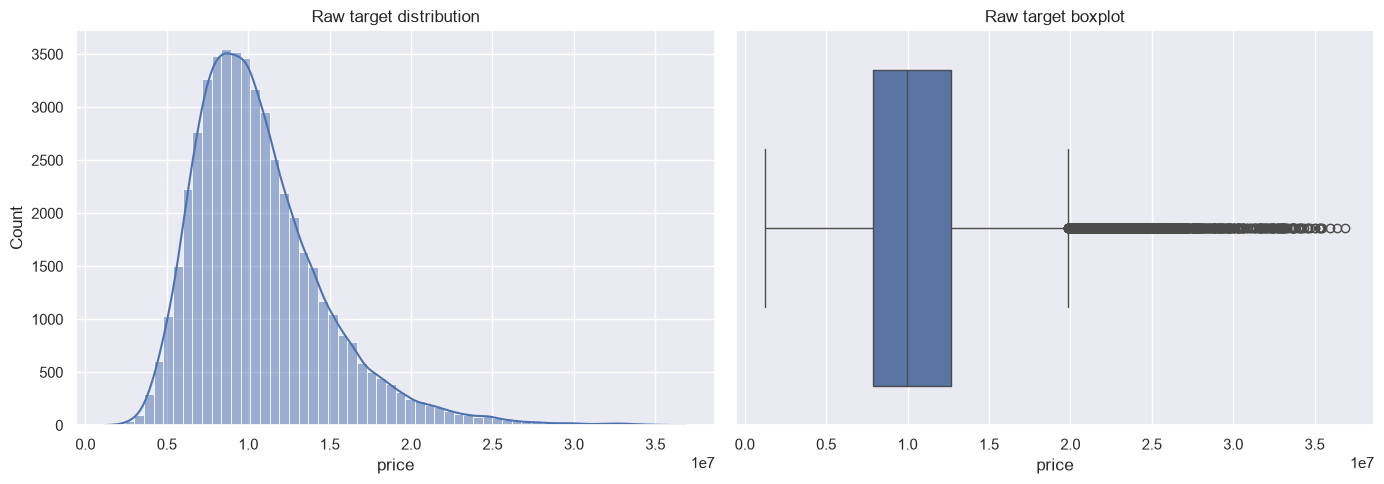

In [10]:
target_for_eda = pd.to_numeric(df_raw[TARGET], errors="coerce")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(target_for_eda.dropna(), bins=60, kde=True, ax=axes[0])
axes[0].set_title("Raw target distribution")
sns.boxplot(x=target_for_eda.dropna(), ax=axes[1])
axes[1].set_title("Raw target boxplot")
plt.tight_layout()
plt.show()

In [11]:
df = df_raw.copy()

NUMERIC_COLUMNS = [
    "area_sqft", "bedrooms", "bathrooms", "property_age_years",
    "distance_to_city_km", "parking", "stories", "school_rating", "price"
]
CATEGORICAL_COLUMNS = ["location_tier", "furnishing_status", "property_type"]

In [12]:
for col in NUMERIC_COLUMNS:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [13]:
valid_ranges = {
    "area_sqft": (250, 8000),
    "bedrooms": (1, 10),
    "bathrooms": (1, 8),
    "property_age_years": (0, 100),
    "distance_to_city_km": (0, 80),
    "parking": (0, 6),
    "stories": (1, 6),
    "school_rating": (1, 10),
    "price": (100_000, 100_000_000)
}


invalid_counts = {}
for col, (low, high) in valid_ranges.items():
    bad = df[col].notna() & ~df[col].between(low, high)
    invalid_counts[col] = int(bad.sum())
    df.loc[bad, col] = np.nan

In [14]:
def normalize_text(series):
    return (series.astype("string").str.strip().str.lower()
            .str.replace(r"[_-]+", " ", regex=True)
            .str.replace(r"\s+", " ", regex=True)) 

category_maps = {
    "location_tier": {
        "tier 1":"Tier 1", "tier1":"Tier 1", "tier 2":"Tier 2", "tier2":"Tier 2",
        "tier 3":"Tier 3", "tier3":"Tier 3", "tier 4":"Tier 4", "tier4":"Tier 4"
    },
    "furnishing_status": {
        "unfurnished":"Unfurnished", "semi furnished":"Semi-furnished",
        "semifurnished":"Semi-furnished", "furnished":"Furnished"
    },
    "property_type": {
        "apartment":"Apartment", "independent house":"Independent House",
        "villa":"Villa", "row house":"Row House"
    }
}    

In [15]:
for col in CATEGORICAL_COLUMNS:
    normalized = normalize_text(df[col])
    df[col] = normalized.map(category_maps[col])

print("Invalid values converted to NaN:")
display(pd.Series(invalid_counts, name="invalid_count").to_frame())
print("Rows before duplicate removal:", len(df))
df = df.drop_duplicates().copy()
print("Rows after duplicate removal:", len(df))
print("Rows with missing target to remove:", int(df[TARGET].isna().sum()))
df = df.loc[df[TARGET].notna()].copy()
print("Cleaned modelling table:", df.shape)
display(df.head())

Invalid values converted to NaN:


,invalid_count
area_sqft,80
bedrooms,170
bathrooms,221
property_age_years,529
distance_to_city_km,276
parking,192
stories,178
school_rating,419
price,0


Rows before duplicate removal: 50000
Rows after duplicate removal: 50000
Rows with missing target to remove: 400
Cleaned modelling table: (49600, 12)


,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,parking,stories,location_tier,furnishing_status,property_type,school_rating,price
0,1753.0,4.0,2.0,8.5,11.13,NaN,3.0,Tier 1,Furnished,Independent House,8.0,13965211.0
1,805.0,2.0,2.0,3.5,6.61,2.0,2.0,Tier 2,Unfurnished,Apartment,6.0,7658858.0
3,1054.0,2.0,2.0,NaN,3.92,NaN,2.0,Tier 1,Unfurnished,Independent House,NaN,10024557.0
4,1373.0,2.0,1.0,4.3,NaN,2.0,1.0,Tier 3,Semi-furnished,Independent House,6.3,9971621.0
5,1562.0,NaN,2.0,17.8,6.28,1.0,1.0,Tier 2,NaN,Independent House,6.4,10899629.0


,missing_count,missing_pct
property_age_years,7070,14.25
school_rating,6377,12.86
distance_to_city_km,5440,10.97
furnishing_status,5332,10.75
bathrooms,4930,9.94
parking,4772,9.62
location_tier,4561,9.20
bedrooms,4247,8.56
stories,3705,7.47
property_type,3700,7.46


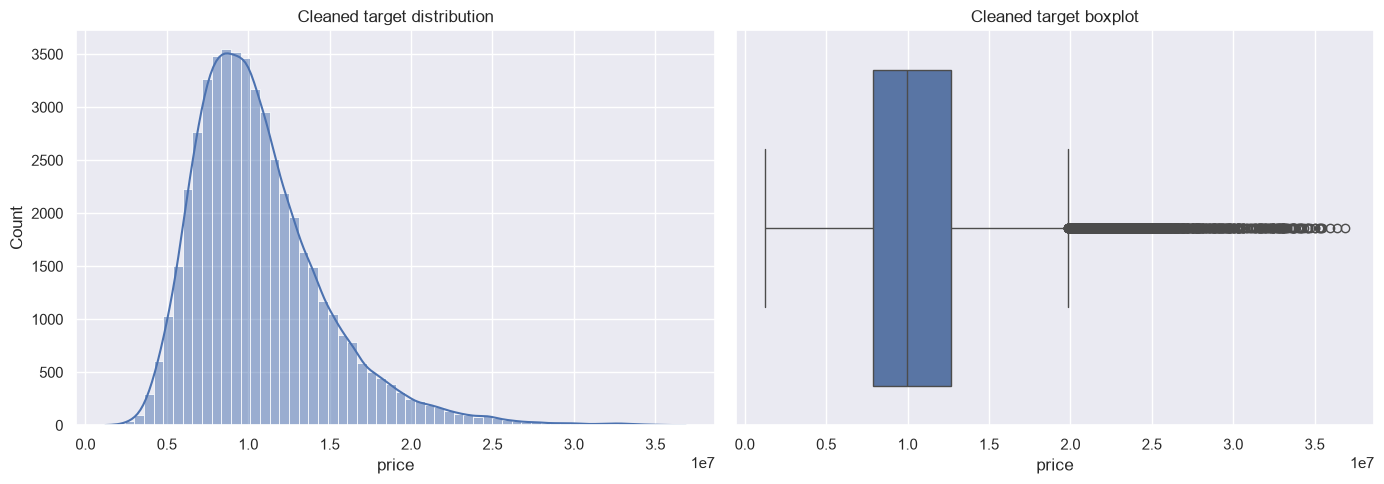

In [16]:
clean_nulls = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean()*100).round(2)
}).sort_values("missing_pct", ascending=False)
display(clean_nulls)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["price"], bins=60, kde=True, ax=axes[0])
axes[0].set_title("Cleaned target distribution")
sns.boxplot(x=df["price"], ax=axes[1])
axes[1].set_title("Cleaned target boxplot")
plt.tight_layout()
plt.show()

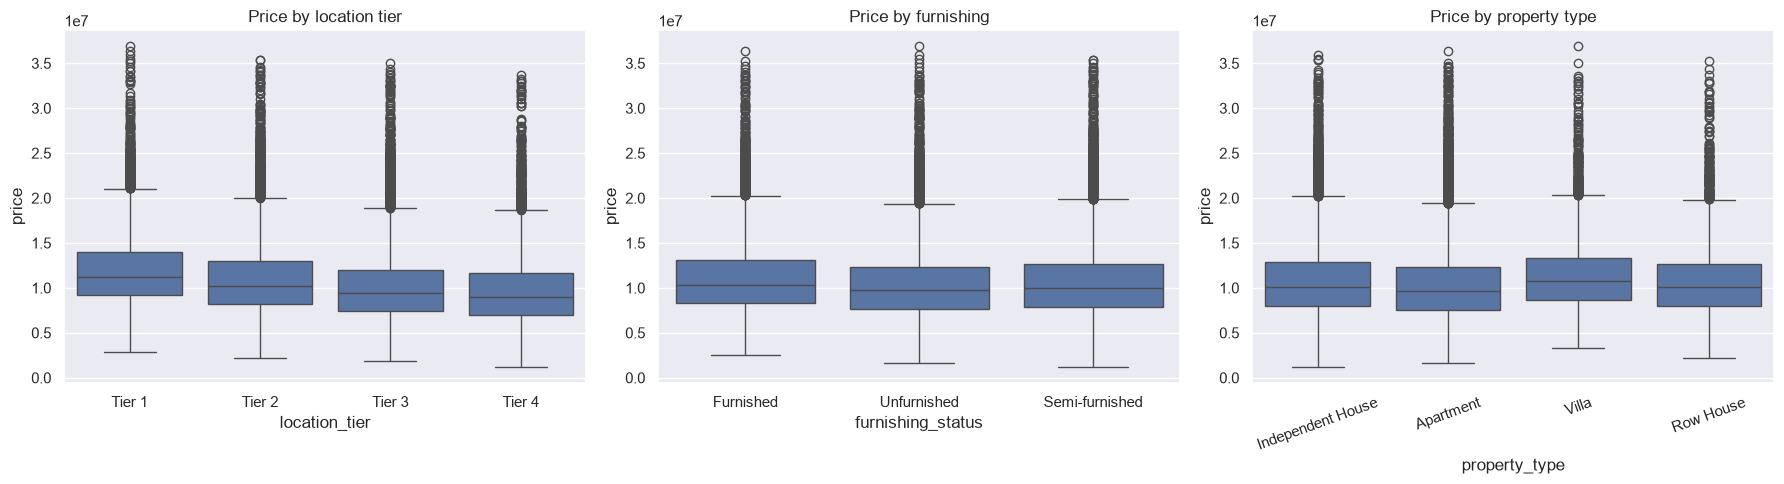

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x="location_tier", y="price", ax=axes[0])
axes[0].set_title("Price by location tier")
sns.boxplot(data=df, x="furnishing_status", y="price", ax=axes[1])
axes[1].set_title("Price by furnishing")
sns.boxplot(data=df, x="property_type", y="price", ax=axes[2])
axes[2].tick_params(axis="x", rotation=20)
axes[2].set_title("Price by property type")
plt.tight_layout()
plt.show()

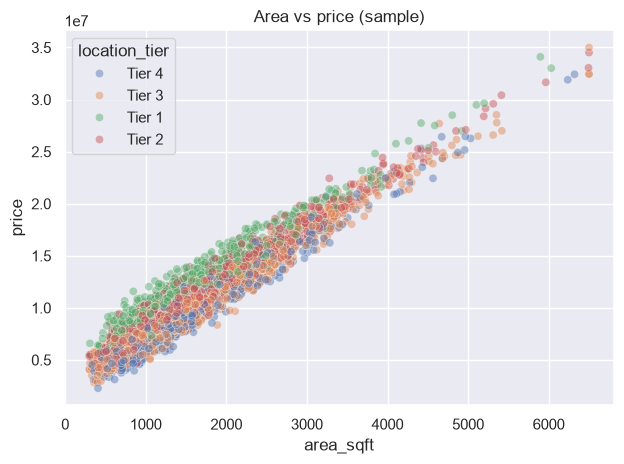

In [19]:
sample = df.sample(min(6000, len(df)), random_state=RANDOM_STATE)
sns.scatterplot(data=sample, x="area_sqft", y="price", hue="location_tier", alpha=.45)
plt.title("Area vs price (sample)")
plt.tight_layout()
plt.show()

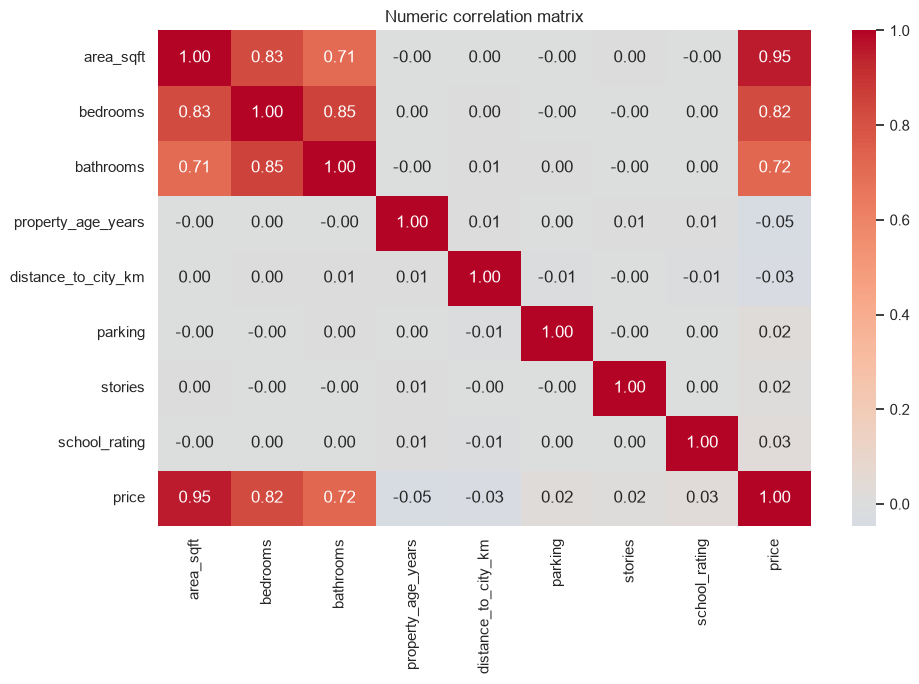

In [20]:
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numeric correlation matrix")
plt.tight_layout()
plt.show()

In [21]:
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

In [22]:
def add_features(frame):
    out = frame.copy()
    out["area_per_bedroom"] = out["area_sqft"] / out["bedrooms"].replace(0, np.nan)
    out["bathrooms_per_bedroom"] = out["bathrooms"] / out["bedrooms"].replace(0, np.nan)
    return out

In [25]:
X = add_features(X)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Train: (39680, 13) | Test: (9920, 13)
Numeric features: ['area_sqft', 'bedrooms', 'bathrooms', 'property_age_years', 'distance_to_city_km', 'parking', 'stories', 'school_rating', 'area_per_bedroom', 'bathrooms_per_bedroom']
Categorical features: ['location_tier', 'furnishing_status', 'property_type']


In [26]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])


categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
], remainder="drop")

In [27]:
print("Numeric missing values in training set:", int(X_train[numeric_features].isna().sum().sum()))
print("Categorical missing values in training set:", int(X_train[categorical_features].isna().sum().sum()))
print("Pipeline configured. Imputation/encoding are fitted inside each training fold.")

Numeric missing values in training set: 44534
Categorical missing values in training set: 10870
Pipeline configured. Imputation/encoding are fitted inside each training fold.


In [28]:
baseline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", DummyRegressor(strategy="median"))
])
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

In [29]:
def metric_dict(y_true, pred):
    return {
        "MAE": mean_absolute_error(y_true, pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
        "R2": r2_score(y_true, pred)
    }
display(pd.DataFrame([metric_dict(y_test, baseline_pred)], index=["Dummy median baseline"]))

,MAE,RMSE,R2
Dummy median baseline,3.046050e+06,4.185577e+06,-0.032075


In [30]:
candidate_estimators = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(n_estimators=120, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesRegressor(n_estimators=120, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(max_iter=140, learning_rate=.08, l2_regularization=1.0, random_state=RANDOM_STATE)
}

In [31]:
fitted = {}
rows = []
for name, estimator in candidate_estimators.items():
    pipe = Pipeline(steps=[("preprocessor", clone(preprocessor)), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    rows.append({"model": name, **metric_dict(y_test, pred)})
model_results = pd.DataFrame(rows).sort_values("RMSE")
display(model_results)

,model,MAE,RMSE,R2
4,Hist Gradient Boosting,725255.575260,9.848215e+05,0.942863
2,Random Forest,760413.252517,1.024733e+06,0.938138
3,Extra Trees,771763.889507,1.040605e+06,0.936207
1,Ridge,795896.305864,1.168217e+06,0.919602
0,Linear Regression,795754.504334,1.168222e+06,0.919601


In [32]:
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_pipe = Pipeline(steps=[("preprocessor", clone(preprocessor)), ("model", Ridge(alpha=10.0))])
scores = cross_validate(
    cv_pipe, X_train, y_train, cv=cv, n_jobs=-1,
    scoring={"mae":"neg_mean_absolute_error", "rmse":"neg_root_mean_squared_error", "r2":"r2"},
    return_train_score=False
)


print(f"CV MAE:  {-scores['test_mae'].mean():,.0f} ± {scores['test_mae'].std():,.0f}")
print(f"CV RMSE: {-scores['test_rmse'].mean():,.0f} ± {scores['test_rmse'].std():,.0f}")
print(f"CV R²:    {scores['test_r2'].mean():.4f} ± {scores['test_r2'].std():.4f}")

CV MAE:  803,094 ± 7,745
CV RMSE: 1,152,260 ± 23,284
CV R²:    0.9200 ± 0.0048


In [33]:
search_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))
])


param_distributions = {
    "model__n_estimators": [100, 160, 220],
    "model__max_depth": [None, 12, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.7, 1.0]
}

In [34]:
search = RandomizedSearchCV(
    search_pipeline, param_distributions=param_distributions,
    n_iter=6, cv=3, scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1, refit=True
)

search.fit(X_train, y_train)
print("Best CV RMSE:", round(-search.best_score_, 2))
print("Best parameters:", search.best_params_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best CV RMSE: 1029959.35
Best parameters: {'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 0.7, 'model__max_depth': 30}


In [35]:
try:
    final_model = search.best_estimator_
    final_model_name = "Tuned Random Forest"
except NameError:
    best_name = model_results.iloc[0]["model"]
    final_model = fitted[best_name]
    final_model_name = best_name

test_pred = final_model.predict(X_test)
final_metrics = metric_dict(y_test, test_pred)
print("Final model:", final_model_name)
display(pd.DataFrame([final_metrics], index=[final_model_name]))

Final model: Tuned Random Forest


,MAE,RMSE,R2
Tuned Random Forest,753620.118649,1.013380e+06,0.939501


In [42]:
comparison = []

for model_name, model_pipeline in fitted.items():
    predictions = model_pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    comparison.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2,
        "R2 (%)": r2 * 100
    })

metrics_df = pd.DataFrame(comparison)
metrics_df = metrics_df.sort_values(
    by="RMSE", ascending=True
).reset_index(drop=True)

display(
    metrics_df.style.format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "R2 Score": "{:.4f}",
        "R2 (%)": "{:.2f}%"
    }).highlight_min(
        subset=["MAE", "RMSE"], color="lightgreen"
    ).highlight_max(
        subset=["R2 Score", "R2 (%)"], color="lightgreen"
    )
)


,Model,MAE,RMSE,R2 Score,R2 (%)
0,Hist Gradient Boosting,"725,255.58","984,821.50",0.9429,94.29%
1,Random Forest,"760,413.25","1,024,733.13",0.9381,93.81%
2,Extra Trees,"771,763.89","1,040,604.60",0.9362,93.62%
3,Ridge,"795,896.31","1,168,217.10",0.9196,91.96%
4,Linear Regression,"795,754.50","1,168,222.15",0.9196,91.96%


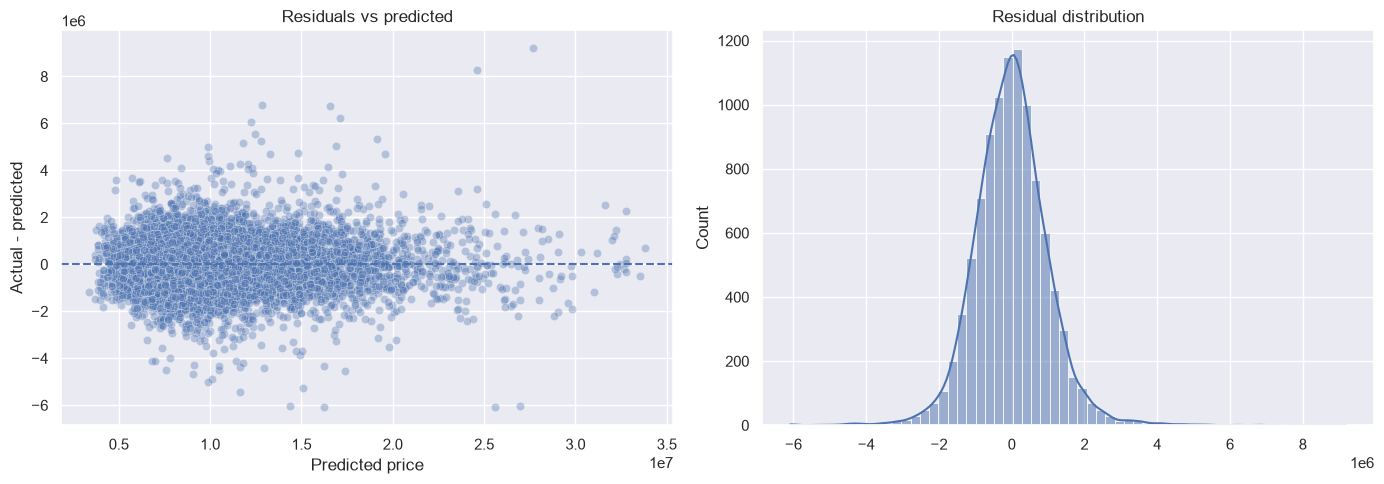

In [36]:
residuals = y_test.to_numpy() - test_pred
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=test_pred, y=residuals, alpha=.35, ax=axes[0])
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Predicted price"); axes[0].set_ylabel("Actual - predicted")
axes[0].set_title("Residuals vs predicted")
sns.histplot(residuals, bins=60, kde=True, ax=axes[1])
axes[1].set_title("Residual distribution")
plt.tight_layout(); plt.show()

In [37]:
error_table = X_test.copy()
error_table["actual_price"] = y_test
error_table["predicted_price"] = test_pred
error_table["absolute_error"] = np.abs(error_table["actual_price"] - error_table["predicted_price"])
error_table["absolute_percentage_error"] = error_table["absolute_error"] / error_table["actual_price"] * 100
display(error_table.groupby("location_tier", dropna=False).agg(
    rows=("actual_price", "size"),
    MAE=("absolute_error", "mean"),
    median_absolute_error=("absolute_error", "median"),
    mean_absolute_percentage_error=("absolute_percentage_error", "mean")
).sort_values("MAE"))
display(error_table.nlargest(10, "absolute_error")[["actual_price", "predicted_price", "absolute_error", "absolute_percentage_error"]])

,rows,MAE,median_absolute_error,mean_absolute_percentage_error
location_tier,,,,
Tier 2,2756,715195.804908,567586.394193,7.245786
Tier 3,3255,728200.524928,589989.122792,8.288204
Tier 4,1451,733558.145305,588413.704072,8.996598
Tier 1,1550,786101.108115,621243.953192,7.019235
NaN,908,937984.189002,762638.678430,9.814517


,actual_price,predicted_price,absolute_error,absolute_percentage_error
43332,36866817.0,2.767282e+07,9.194002e+06,24.938420
32852,32883389.0,2.461453e+07,8.268858e+06,25.146004
23001,19623597.0,1.284432e+07,6.779273e+06,34.546537
3441,23318774.0,1.655616e+07,6.762610e+06,29.000711
20672,23329689.0,1.708893e+07,6.240760e+06,26.750293
10156,10154877.0,1.624493e+07,6.090056e+06,59.971735
24666,18301556.0,1.222081e+07,6.080748e+06,33.225305
7399,19530372.0,2.559097e+07,6.060602e+06,31.031678
38577,8307033.0,1.434711e+07,6.040075e+06,72.710375
7534,20905913.0,2.694006e+07,6.034150e+06,28.863366


,feature,importance_mean,importance_std
0,area_sqft,3.594570e+06,46222.658398
1,bedrooms,8.001207e+05,24813.984959
7,location_tier,3.872604e+05,1906.975115
2,bathrooms,1.489428e+05,51447.126899
9,property_type,7.572713e+04,6931.344402
11,area_per_bedroom,4.996912e+04,2912.301194
8,furnishing_status,2.473627e+04,979.562002
3,property_age_years,2.362899e+04,3587.446425
5,parking,6.513006e+03,1095.797911
4,distance_to_city_km,4.979694e+03,4305.569838


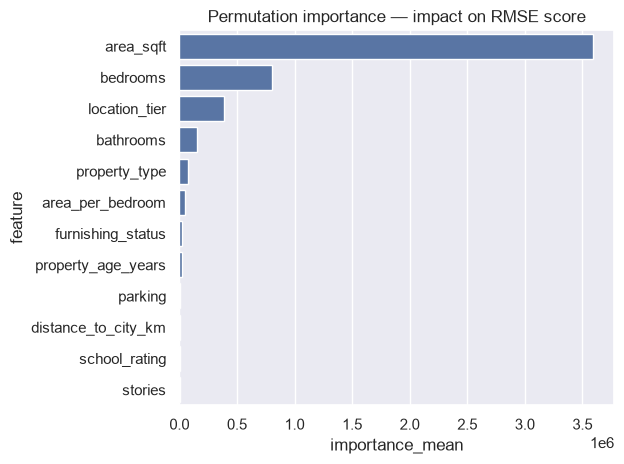

In [38]:
imp_X = X_test.sample(min(2500, len(X_test)), random_state=RANDOM_STATE)
imp_y = y_test.loc[imp_X.index]
perm = permutation_importance(
    final_model, imp_X, imp_y, n_repeats=3,
    scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=-1
)


importance = pd.DataFrame({
    "feature": imp_X.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance)

sns.barplot(data=importance.head(12), x="importance_mean", y="feature")
plt.title("Permutation importance — impact on RMSE score")
plt.tight_layout(); plt.show()

In [40]:
mlp_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", MLPRegressor(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=0.001,
        batch_size=512,
        learning_rate_init=0.001,
        max_iter=80,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=8,
        random_state=RANDOM_STATE
    ))
])


mlp_pipeline.fit(X_train, y_train)
mlp_pred = mlp_pipeline.predict(X_test)
mlp_metrics = metric_dict(y_test, mlp_pred)
display(pd.DataFrame([mlp_metrics], index=["MLP Neural Network"]))

,MAE,RMSE,R2
MLP Neural Network,2.116113e+06,2.649024e+06,0.586598


In [41]:
MODEL_PATH = Path("house_price_enterprise_pipeline.joblib")
joblib.dump(final_model, MODEL_PATH)
print("Saved model:", MODEL_PATH.resolve())

new_property = pd.DataFrame([{
    "area_sqft": 1500,
    "bedrooms": 3,
    "bathrooms": 2,
    "property_age_years": 8,
    "distance_to_city_km": 5.5,
    "parking": 1,
    "stories": 2,
    "location_tier": "Tier 2",
    "furnishing_status": "Semi-furnished",
    "property_type": "Apartment",
    "school_rating": 7.2
}])
new_property = add_features(new_property)
loaded_pipeline = joblib.load(MODEL_PATH)
predicted_price = loaded_pipeline.predict(new_property)[0]
print(f"Predicted synthetic price: {predicted_price:,.0f}")

Saved model: C:\Users\anami\HPP\house_price_enterprise_pipeline.joblib
Predicted synthetic price: 10,798,467
